# Calculate inverse emissions

## Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import openscm_units
import pandas as pd
import pandas_indexing as pix
import pint.testing
import pint_xarray
import xarray as xr
from attrs import evolve

from cmip7_scenariomip_ghg_generation.constants import GHG_LIFETIMES, GHG_MOLECULAR_MASSES
from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation import mean_preserving_interpolation
from cmip7_scenariomip_ghg_generation.mean_preserving_interpolation.annual_to_monthly import DEFAULT_ALGORITHM

## Parameters

In [2]:
ghg: str = "halon2402"
monthly_mean_file: str = (
    "../output-bundles/dev-test/data/interim/monthly-means/single-concentration-projection_halon2402_monthly-mean.nc"
)
out_file: str = "../output-bundles/dev-test/data/interim/inverse-emissions/single-concentration-projection_halon2402_inverse-emissions.feather"  # noqa: E501

In [3]:
# Parameters
ghg = "ccl4"
monthly_mean_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/monthly-means/single-concentration-projection_ccl4_monthly-mean.nc"
out_file = "/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/inverse-emissions/single-concentration-projection_ccl4_inverse-emissions.feather"


## Parse parameters

In [4]:
monthly_mean_file_p = Path(monthly_mean_file)
out_file_p = Path(out_file)

## Set up

In [5]:
ur = pint_xarray.setup_registry(openscm_units.unit_registry)
Q = ur.Quantity
ur.setup_matplotlib(enable=True)

## Load data

### Monthly-mean file

In [6]:
monthly_mean = xr.load_dataarray(monthly_mean_file_p, use_cftime=True).pint.quantify(unit_registry=ur)
monthly_mean

Magnitude,[[0.0 0.0 0.0 ... 56.831608315603965 56.83160831905651 56.83160832248779]]
Units,ppt


## Invert

### Interpolate to higher resolution

This minimises the discretisation issue.

In [7]:
MONTHS_PER_YEAR = 12.0
res_increase = 30

In [8]:
x_bounds_in = np.array([v.year * MONTHS_PER_YEAR + v.month - 1 for v in monthly_mean["time"].values], dtype=np.float64)
x_bounds_in = Q(np.hstack([x_bounds_in, x_bounds_in[-1] + 1]), "month")
x_bounds_in.to("yr")

Magnitude,[1750.0 1750.0833333333333 1750.1666666666665 ... 2500.833333333333 2500.9166666666665 2501.0]
Units,yr


In [9]:
high_res_step = 1 / res_increase
res_increaser = Q(np.arange(0, 1, high_res_step), x_bounds_in.u)
x_bounds_out = (x_bounds_in[:-1, np.newaxis] + res_increaser[np.newaxis, :]).flatten()
x_bounds_out = np.round(np.hstack([x_bounds_out, x_bounds_out[-1] + res_increaser[1]]), 8)

pint.testing.assert_equal(
    x_bounds_in[-1],
    x_bounds_out[-1],
)

x_bounds_out.to("yr")

Magnitude,[1750.0 1750.0027777775 1750.0055555558333 ... 2500.994444444166 2500.9972222224997 2501.0]
Units,yr


In [10]:
if monthly_mean["scenario"].size != 1:
    msg = (
        "Should only be doing this for single concentration projection gases " "i.e. there should only be one scenario"
    )
    raise AssertionError(msg)

y_in = monthly_mean.data.squeeze()
y_in

Magnitude,[0.0 0.0 0.0 ... 56.831608315603965 56.83160831905651 56.83160832248779]
Units,ppt


In [11]:
algorithm = evolve(DEFAULT_ALGORITHM)

In [12]:
# papermill_description=calculate-high-res-values
high_res_vals = mean_preserving_interpolation(
    x_bounds_in=x_bounds_in,
    y_in=y_in,
    x_bounds_out=x_bounds_out,
    algorithm=algorithm,
    verify_output_is_mean_preserving=True,
    rtol=1e-8,
)
high_res_vals

Calculating output values:   0%|          | 0/270360 [00:00<?, ?it/s]

Updating intervals where the solution is less than the minimum value:   0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

Magnitude,[0.0 0.0 0.0 ... 56.831608323898266 56.83160832400996 56.83160832412235]
Units,ppt


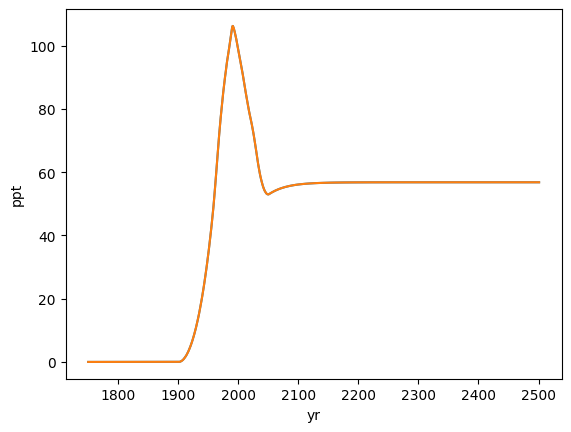

In [13]:
fig, ax = plt.subplots()

ax.plot((x_bounds_out[1:] + x_bounds_out[:-1]) / 2.0, high_res_vals)
ax.plot((x_bounds_in[1:] + x_bounds_in[:-1]) / 2.0, y_in)
ax.xaxis.set_units(ur.yr)
# ax.set_xlim([2025, 2030])

### Invert using one-box model

We assume that the gas' atmospheric concentration can be modelled by a simple one-box model

$$
\frac{dC}{dt} = \alpha E - \frac{C}{\tau}
$$

Given we have the concentrations, we can solve for emissions.

In [14]:
dC_approx = high_res_vals[1:] - high_res_vals[:-1]
# constant gradient for last step
dC_approx = np.hstack([dC_approx, dC_approx[-1]])
dt_approx = x_bounds_out[1:] - x_bounds_out[:-1]
dC_dt = dC_approx / dt_approx
# dC_dt

In [15]:
tau = GHG_LIFETIMES[ghg]
# tau

In [16]:
alpha_emms_high_res = dC_dt + high_res_vals / tau
# # Get rid of any negative values
# alpha_emms_high_res[np.where(alpha_emms_high_res.m < 0.0)] = alpha_emms_high_res[0] * 0.0
# alpha_emms_high_res

In [17]:
# Aggregate up to yearly, which is what we care about
# (sort of smoothing)
years = np.unique(monthly_mean["time"].dt.year)
alpha_emms_monthly = (alpha_emms_high_res.reshape(-1, res_increase) * dt_approx.reshape(-1, res_increase)).sum(axis=1)
alpha_emms_yearly = (alpha_emms_monthly.reshape(-1, int(MONTHS_PER_YEAR))).sum(axis=1) / Q(1, "yr")
# Get rid of small negative values
small_val = 1e-8
alpha_emms_yearly[
    ((alpha_emms_yearly < 0.0) & (alpha_emms_yearly > np.max(alpha_emms_yearly) * -10e-2))
    | (np.abs(alpha_emms_yearly).m < small_val)
] = alpha_emms_yearly[0] * 0.0
if ghg == "halon1202":
    alpha_emms_yearly[alpha_emms_yearly < 0.0] = alpha_emms_yearly[0] * 0.0

# alpha_emms_yearly

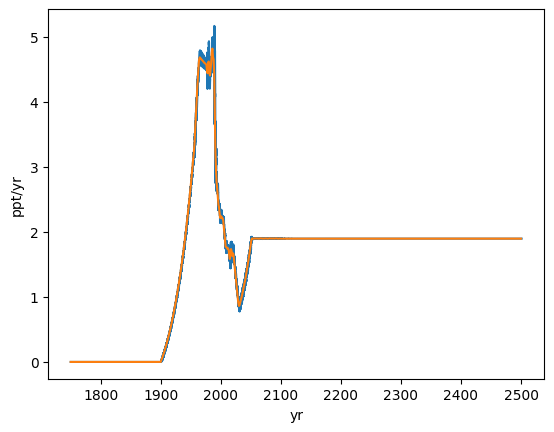

In [18]:
fig, ax = plt.subplots()

ax.plot((x_bounds_out[1:] + x_bounds_out[:-1]) / 2.0, alpha_emms_high_res)
ax.plot(years, alpha_emms_yearly)
ax.yaxis.set_units(ur.Unit("ppt / yr"))
ax.xaxis.set_units(ur.Unit("yr"))
# ax.set_xlim([2023, 2030])

### Check results of running inversion back through the model

In [19]:
run_res = Q(np.zeros_like(years), y_in.u) * np.nan
run_res[0] = Q(np.mean(y_in.m[: int(MONTHS_PER_YEAR)]), y_in.u)
for i in range(years.size - 1):
    dC_dt = alpha_emms_yearly[i] - run_res[i] / tau

    run_res[i + 1] = run_res[i] + (Q(1, "yr") * dC_dt)

# run_res

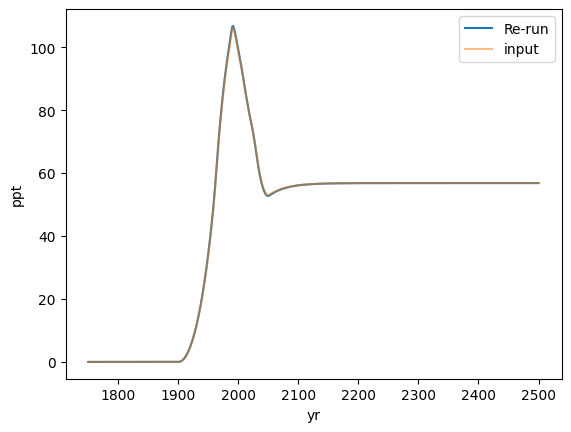

In [20]:
fig, ax = plt.subplots()

ax.plot(years, run_res, label="Re-run")
ax.plot((x_bounds_in[1:] + x_bounds_in[:-1]) / 2.0, y_in, label="input", alpha=0.5)
ax.xaxis.set_units(ur.yr)
ax.legend()
# ax.set_xlim([2025, 2030])

## Prepare output

In [21]:
out_ppt_yr = pd.DataFrame(
    alpha_emms_yearly.m[:, np.newaxis].T,
    columns=years,
    index=pd.MultiIndex.from_tuples(
        [(ghg, str(alpha_emms_yearly.u), "inverse_emissions")], names=["ghg", "unit", "variable"]
    ),
)
if (out_ppt_yr < 0.0).any().any():
    raise AssertionError(out_ppt_yr.min().min())

out_ppt_yr

,,,1750,1751,1752,1753,1754,1755,1756,1757,1758,1759,...,2491,2492,2493,2494,2495,2496,2497,2498,2499,2500
ghg,unit,variable,,,,,,,,,,,,,,,,,,,,,
ccl4,ppt / yr,inverse_emissions,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.894387,1.894387,1.894387,1.894387,1.894387,1.894387,1.894387,1.894387,1.894387,1.894387


In [22]:
# CDIAC https://web.archive.org/web/20170118004650/http://cdiac.ornl.gov/pns/convert.html
ATMOSPHERE_MASS = Q(5.137 * 10**18, "kg")
# https://www.engineeringtoolbox.com/molecular-mass-air-d_679.html
MOLAR_MASS_DRY_AIR = Q(28.9, "g / mol")
atm_moles = (ATMOSPHERE_MASS / MOLAR_MASS_DRY_AIR).to("mole")
# Lines up with CDIAC: https://web.archive.org/web/20170118004650/http://cdiac.ornl.gov/pns/convert.html
fraction_factor = Q(1e-6, "1 / ppm")
mass_one_ppm_co2 = atm_moles * fraction_factor * Q(12.01, "gC / mole")
cdiac_expected = 2.13
if np.round(mass_one_ppm_co2.to("GtC / ppm").m, 2) != cdiac_expected:
    raise AssertionError

In [23]:
molecular_mass = GHG_MOLECULAR_MASSES[ghg]
alpha = 1 / (atm_moles * fraction_factor * molecular_mass)
emms_unit = str(molecular_mass.u).replace(" / mole", "").replace("g", "t") + " / yr"
emms_yearly = (alpha_emms_yearly / alpha).to(emms_unit)
# emms_yearly

In [24]:
out_t_yr = pd.DataFrame(
    emms_yearly.m[:, np.newaxis].T,
    columns=years,
    index=pd.MultiIndex.from_tuples(
        [(ghg, str(emms_yearly.u), "inverse_emissions")], names=["ghg", "unit", "variable"]
    ),
)
# out_t_yr

In [25]:
if out_ppt_yr.shape[0] != 1 or out_t_yr.shape[0] != 1:
    msg = (
        "Should only be doing this for single concentration projection gases " "i.e. there should only be one scenario"
    )
    raise AssertionError(msg)

out = pix.concat([out_ppt_yr, out_t_yr]).pix.assign(scenario="all")
out

1750  1751  1752  1753  1754  \
ghg  unit       variable          scenario                                 
ccl4 ppt / yr   inverse_emissions all        0.0   0.0   0.0   0.0   0.0   
     tCCl4 / yr inverse_emissions all        0.0   0.0   0.0   0.0   0.0   

                                            1755  1756  1757  1758  1759  ...  \
ghg  unit       variable          scenario                                ...   
ccl4 ppt / yr   inverse_emissions all        0.0   0.0   0.0   0.0   0.0  ...   
     tCCl4 / yr inverse_emissions all        0.0   0.0   0.0   0.0   0.0  ...   

                                                    2491          2492  \
ghg  unit       variable          scenario                               
ccl4 ppt / yr   inverse_emissions all           1.894387      1.894387   
     tCCl4 / yr inverse_emissions all       51792.275874  51792.275874   

                                                    2493          2494  \
ghg  unit       variable          scenario                               
ccl4 ppt / yr   inverse_emissions all           1.894387      1.894387   
     tCCl4 / yr inverse_emissions all       51792.275874  51792.275874   

                                                    2495          2496  \
ghg  unit       variable          scenario                               
ccl4 ppt / yr   inverse_emissions all           1.894387      1.894387   
     tCCl4 / yr inverse_emissions all       51792.275874  51792.275874   

                                                    2497          2498  \
ghg  unit       variable          scenario                               
ccl4 ppt / yr   inverse_emissions all           1.894387      1.894387   
     tCCl4 / yr inverse_emissions all       51792.275874  51792.275874   

                                                    2499          2500  
ghg  unit       variable          scenario                              
ccl4 ppt / yr   inverse_emissions all           1.894387      1.894387  
     tCCl4 / yr inverse_emissions all       51792.275891  51792.275949  

[2 rows x 751 columns]

## Save

In [26]:
out_file_p.parent.mkdir(exist_ok=True, parents=True)
out.to_feather(out_file_p)
out_file_p

PosixPath('/Users/znicholls/Documents/repos/cmip7-scenariomip-ghg-concentrations/output-bundles/1.1.0/data/interim/inverse-emissions/single-concentration-projection_ccl4_inverse-emissions.feather')